# Beauty Intelligence: a distributed consumer-analytics pipeline in PySpark

**IDS 706 · Week 12 Mini Assignment** · Shahad Baalkhashir

**Data:** Amazon Reviews 2023, *Beauty & Personal Care* category (McAuley Lab, UC San Diego).
This run uses **4.53 GB of review JSONL** (the first ~9.6M reviews of the 11 GB file; the download stalled on a slow connection) and the **complete 2.84 GB product metadata file** (~1M products): **7.37 GB of raw JSON in total**.

**Questions this notebook answers**
1. Which beauty sub-categories are growing, and are ratings inflating over time?
2. Do verified buyers rate products differently from unverified reviewers?
3. Which products look **overrated** (unverified reviews much more positive than verified ones)?
4. Does a higher price buy higher satisfaction?
5. Which brands give the best ratings in each sub-category?

**Pipeline layout (medallion style)**
`raw JSONL` → `scripts/01_bronze_ingest.py` → **bronze Parquet** (reviews partitioned by year) → *this notebook* → **gold Parquet** outputs in `output/`

## 0. Setup
We start a local Spark session that uses all CPU cores. Event logging is turned on so the Spark UI (History Server) can show every query after the notebook finishes.

In [1]:
import os, time, glob
from pyspark.sql import SparkSession, functions as F, Window

ROOT = os.path.abspath("..")
BRONZE = os.path.join(ROOT, "data", "bronze")
RAW = os.environ.get("RAW_DIR", os.path.join(ROOT, "data", "raw"))
OUT = os.path.join(ROOT, "output")
EVENT_DIR = os.path.expanduser("~/.spark-events")   # no spaces in path, needed by the event log URI
os.makedirs(EVENT_DIR, exist_ok=True)
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")

spark = (
    SparkSession.builder.appName("beauty-intelligence")
    .master("local[*]")
    .config("spark.driver.memory", "12g")
    .config("spark.sql.shuffle.partitions", "64")       # default 200 is too many for one laptop
    .config("spark.sql.adaptive.enabled", "true")        # AQE: re-plans at runtime using real sizes
    .config("spark.ui.showConsoleProgress", "false")   # keep notebook output clean
    .config("spark.eventLog.enabled", "true")
    .config("spark.eventLog.dir", "file://" + EVENT_DIR)
    .getOrCreate()
)
sc = spark.sparkContext
sc.setLogLevel("WARN")
print("Spark", spark.version, "| cores:", sc.defaultParallelism, "| UI:", sc.uiWebUrl, "| app id:", sc.applicationId)

def timed(label, fn):
    """Run fn(), print wall-clock seconds, return (result, seconds)."""
    sc.setJobDescription(label)                       # names the query in the Spark UI
    t0 = time.time(); r = fn(); s = time.time() - t0
    print(f"{label:<55s} {s:7.2f} s"); return r, s

def du(path):
    return sum(os.path.getsize(f) for f in glob.glob(os.path.join(path, "**", "*"), recursive=True) if os.path.isfile(f)) / 1e9

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/24 20:31:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.3 | cores: 10 | UI: http://localhost:4040 | app id: local-1795570274807


## 1. Load the data
The raw JSON was converted once to Parquet by `scripts/01_bronze_ingest.py`. Parquet is **columnar** (each column stored separately) and **compressed**, so Spark can skip columns and files it does not need. Reviews are written in one folder per year (`review_year=2021/…`), so filters on year can skip whole folders.

In [2]:
print(f"Raw JSONL on disk      : {du(RAW):6.2f} GB")
print(f"Bronze Parquet on disk : {du(BRONZE):6.2f} GB")

reviews = spark.read.parquet(os.path.join(BRONZE, "reviews"))
products = spark.read.parquet(os.path.join(BRONZE, "products"))
reviews.printSchema()
products.printSchema()

Raw JSONL on disk      :   7.37 GB
Bronze Parquet on disk :   1.81 GB


root
 |-- rating: double (nullable = true)
 |-- title: string (nullable = true)
 |-- text: string (nullable = true)
 |-- asin: string (nullable = true)
 |-- parent_asin: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- helpful_vote: integer (nullable = true)
 |-- verified_purchase: boolean (nullable = true)
 |-- review_ts: timestamp (nullable = true)
 |-- review_year: integer (nullable = true)

root
 |-- parent_asin: string (nullable = true)
 |-- title: string (nullable = true)
 |-- main_category: string (nullable = true)
 |-- sub_category: string (nullable = true)
 |-- leaf_category: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- store: string (nullable = true)
 |-- price: double (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- rating_number: long (nullable = true)



In [3]:
sc.setJobDescription("load: count rows")
n_reviews, _ = timed("count reviews", reviews.count)
n_products, _ = timed("count products", products.count)
sc.setJobDescription("load: distinct reviewers")
print(f"{n_reviews:,} reviews | {n_products:,} products | {reviews.select('user_id').distinct().count():,} reviewers")
sc.setJobDescription("load: reviews per year")
reviews.groupBy("review_year").count().orderBy("review_year").show(30)

count reviews                                              1.90 s


count products                                             0.32 s


9,618,203 reviews | 1,028,914 products | 2,954,002 reviewers


+-----------+-------+
|review_year|  count|
+-----------+-------+
|       NULL|      1|
|       2000|      3|
|       2001|     13|
|       2002|     44|
|       2003|    102|
|       2004|    359|
|       2005|    796|
|       2006|   1051|
|       2007|   2901|
|       2008|   4836|
|       2009|   7616|
|       2010|  14747|
|       2011|  33409|
|       2012|  71018|
|       2013| 205322|
|       2014| 371795|
|       2015| 619217|
|       2016| 763361|
|       2017| 782190|
|       2018| 849967|
|       2019|1117273|
|       2020|1410793|
|       2021|1457437|
|       2022|1490140|
|       2023| 413812|
+-----------+-------+



## 2. Transformations (lazy) vs actions (eager)

* A **transformation** (`filter`, `select`, `withColumn`, `join`, `groupBy`…) only *describes* a new DataFrame. Spark adds it to a plan and **runs nothing**.
* An **action** (`count`, `show`, `collect`, `write`…) asks for a result, so Spark optimizes the whole plan and **launches jobs**.

Below we chain five transformations and time them, then run an action. We also ask Spark's status tracker how many jobs ran in each phase.

In [4]:
tracker = sc.statusTracker()

sc.setJobGroup("lazy", "lazy demo: transformations only")
t0 = time.time()
lazy_df = (reviews
           .filter(F.col("review_year") >= 2020)
           .filter(F.col("rating") <= 2)
           .withColumn("review_len", F.length("text"))
           .select("parent_asin", "rating", "review_len")
           .groupBy("parent_asin").agg(F.avg("review_len").alias("avg_len")))
t_lazy = time.time() - t0
print(f"5 transformations built in {t_lazy*1000:.1f} ms  -> jobs launched: {len(tracker.getJobIdsForGroup('lazy'))}")

sc.setJobGroup("eager", "lazy demo: count() action")
t0 = time.time()
n = lazy_df.count()
t_eager = time.time() - t0
print(f"count() action took {t_eager:.2f} s            -> jobs launched: {len(tracker.getJobIdsForGroup('eager'))}  (result: {n:,} products)")
sc.setJobGroup("main", "pipeline")

5 transformations built in 84.9 ms  -> jobs launched: 0


count() action took 1.51 s            -> jobs launched: 3  (result: 181,823 products)


Calling `.explain()` is also not an action: it prints the *plan* without reading data. The plan below already shows that Spark pushed `review_year >= 2020` into the file scan (**PartitionFilters**) and `rating <= 2` into the Parquet reader (**PushedFilters**). Only the 3 columns we need are read (**ReadSchema**).

In [5]:
lazy_df.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[parent_asin#4], functions=[avg(review_len#103)])
   +- Exchange hashpartitioning(parent_asin#4, 64), ENSURE_REQUIREMENTS, [plan_id=354]
      +- HashAggregate(keys=[parent_asin#4], functions=[partial_avg(review_len#103)])
         +- Project [parent_asin#4, length(text#2) AS review_len#103]
            +- Filter (isnotnull(rating#0) AND (rating#0 <= 2.0))
               +- FileScan parquet [rating#0,text#2,parent_asin#4,review_year#9] Batched: true, DataFilters: [isnotnull(rating#0), (rating#0 <= 2.0)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/Users/shahad/Desktop/Data Engineering - IDS 706/Assignments/Week..., PartitionFilters: [isnotnull(review_year#9), (review_year#9 >= 2020)], PushedFilters: [IsNotNull(rating), LessThanOrEqual(rating,2.0)], ReadSchema: struct<rating:double,text:string,parent_asin:string>




## 3. The pipeline (DataFrame API)

Optimization choices, in order:
1. **Filter early.** The year filter comes first, so whole folders are skipped (*partition pruning*).
2. **Column pruning.** We `select` only the columns we use. The big `text` and `title` columns are never read.
3. **Broadcast join with a slim dimension.** The product table is small after filtering *and* after dropping the long title text, so we send a copy to every executor instead of shuffling the multi-million-row review table. A first version broadcast product titles too, and the broadcast was ~2 KB per product. Titles are now joined only onto the final result rows.
4. **One cached fact table** feeds every later aggregation and SQL query.

In [6]:
# --- Reviews: 2 filters + column pruning + withColumn
reviews_f = (reviews
    .filter(F.col("review_year") >= 2015)                                   # filter 1: partition pruning (2015-2023 window)
    .filter(F.col("rating").isNotNull() & F.col("parent_asin").isNotNull())  # filter 2: data quality
    .select("parent_asin", "user_id", "rating", "helpful_vote",
            "verified_purchase", "review_ts", "review_year")               # column pruning: no text/title
    .withColumn("review_month", F.month("review_ts"))
    .withColumn("is_verified", F.col("verified_purchase").cast("int"))
    .withColumn("sentiment", F.when(F.col("rating") >= 4, "positive")
                              .when(F.col("rating") <= 2, "negative")
                              .otherwise("neutral")))

# --- Products: filter + withColumn
products_f = (products
    .filter(F.col("sub_category").isNotNull() & (F.col("rating_number") >= 5))  # filter 3: categorized, reviewed products
    .withColumn("price_band", F.when(F.col("price").isNull(), "unknown")
                               .when(F.col("price") < 10, "1) <$10")
                               .when(F.col("price") < 25, "2) $10-25")
                               .when(F.col("price") < 50, "3) $25-50")
                               .otherwise("4) $50+"))
    .withColumn("brand", F.lower(F.trim(F.col("brand"))))
    .select("parent_asin", "brand", "sub_category", "price", "price_band",
            "average_rating", "rating_number"))   # slim dimension: long titles are NOT broadcast

# --- Join: big fact x small dimension -> broadcast hash join (no shuffle of reviews)
fact = reviews_f.join(F.broadcast(products_f), on="parent_asin", how="inner")
fact.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (10)
+- Project (9)
   +- BroadcastHashJoin Inner BuildRight (8)
      :- Project (3)
      :  +- Filter (2)
      :     +- Scan parquet  (1)
      +- BroadcastExchange (7)
         +- Project (6)
            +- Filter (5)
               +- Scan parquet  (4)


(1) Scan parquet 
Output [7]: [rating#0, parent_asin#4, user_id#5, helpful_vote#6, verified_purchase#7, review_ts#8, review_year#9]
Batched: true
Location: InMemoryFileIndex [file:/Users/shahad/Desktop/Data Engineering - IDS 706/Assignments/Week 12 Mini Assignment - PySpark/beauty-intelligence-spark/data/bronze/reviews]
PartitionFilters: [isnotnull(review_year#9), (review_year#9 >= 2015)]
PushedFilters: [IsNotNull(rating), IsNotNull(parent_asin)]
ReadSchema: struct<rating:double,parent_asin:string,user_id:string,helpful_vote:int,verified_purchase:boolean,review_ts:timestamp>

(2) Filter
Input [7]: [rating#0, parent_asin#4, user_id#5, helpful_vote#6, verified_purchase#7, review_ts#8, review_ye

### groupBy with aggregations
Brand-level scorecard per year: volume, rating, share of verified purchases and helpful votes.

In [7]:
brand_year = (fact.groupBy("review_year", "sub_category", "brand")
    .agg(F.count("*").alias("n_reviews"),
         F.round(F.avg("rating"), 3).alias("avg_rating"),
         F.round(F.avg("is_verified"), 3).alias("pct_verified"),
         F.sum("helpful_vote").alias("helpful_votes"),
         F.round(F.avg("price"), 2).alias("avg_price"),
         F.countDistinct("parent_asin").alias("n_products"))
    .filter(F.col("n_reviews") >= 50))
sc.setJobDescription("groupBy: brand x sub-category x year scorecard")
brand_year.orderBy(F.desc("n_reviews")).show(10, truncate=40)

+-----------+------------+-------------------+---------+----------+------------+-------------+---------+----------+
|review_year|sub_category|              brand|n_reviews|avg_rating|pct_verified|helpful_votes|avg_price|n_products|
+-----------+------------+-------------------+---------+----------+------------+-------------+---------+----------+
|       2021|      Makeup|maybelline new york|    17091|     3.955|        0.96|         8092|     9.03|       413|
|       2020|      Makeup|maybelline new york|    14798|     4.077|        0.94|        11872|      9.0|       431|
|       2022|      Makeup|maybelline new york|    14010|     3.897|       0.962|        10801|     8.84|       384|
|       2019|      Makeup|maybelline new york|    13449|     4.122|       0.942|        16553|     9.79|       477|
|       2021|   Hair Care|             revlon|    11772|     4.153|       0.938|         3300|    32.25|       173|
|       2020|   Hair Care|             revlon|    10889|     4.307|     

### Caching bonus: does `.cache()` help repeated actions?
`fact` is used by every query that follows. Without caching, **each action re-reads the Parquet files and redoes the join**. We time three actions before and after caching.

In [8]:
def three_actions(df):
    df.count()
    df.groupBy("sub_category").agg(F.avg("rating")).collect()
    df.groupBy("review_year", "sentiment").count().collect()

_, t_nocache = timed("3 actions on fact, NOT cached", lambda: three_actions(fact))
fact.cache()
_, t_fill = timed("first action after cache() (materializes cache)", fact.count)
_, t_cache = timed("3 actions on fact, cached", lambda: three_actions(fact))
print(f"\nSpeed-up from caching: {t_nocache / t_cache:.1f}x")
fact.createOrReplaceTempView("beauty_reviews")
products.createOrReplaceTempView("products")

3 actions on fact, NOT cached                             10.07 s


first action after cache() (materializes cache)           29.05 s


3 actions on fact, cached                                  2.35 s

Speed-up from caching: 4.3x


## 4. Spark SQL queries
The cached `fact` DataFrame is registered as the view `beauty_reviews`. Spark SQL and the DataFrame API compile to the **same Catalyst plan**, so we can use whichever is clearer.

**SQL 1: Category growth and rating inflation by year**

In [9]:
sc.setJobDescription("SQL 1: category growth and rating by year")
q1 = spark.sql("""
    SELECT sub_category, review_year,
           COUNT(*)                         AS n_reviews,
           ROUND(AVG(rating), 3)            AS avg_rating,
           ROUND(AVG(CASE WHEN sentiment = 'negative' THEN 1.0 ELSE 0 END), 3) AS pct_negative
    FROM beauty_reviews
    GROUP BY sub_category, review_year
""")
q1.createOrReplaceTempView("category_year")
spark.sql("""
    SELECT review_year, SUM(n_reviews) AS n_reviews,
           ROUND(SUM(avg_rating * n_reviews) / SUM(n_reviews), 3) AS avg_rating
    FROM category_year GROUP BY review_year ORDER BY review_year
""").show()
q1.filter("review_year = 2022").orderBy(F.desc("n_reviews")).show(truncate=False)

+-----------+---------+----------+
|review_year|n_reviews|avg_rating|
+-----------+---------+----------+
|       2015|   603789|     4.303|
|       2016|   748127|     4.296|
|       2017|   770516|     4.237|
|       2018|   838265|     4.205|
|       2019|  1106369|     4.286|
|       2020|  1402631|     4.211|
|       2021|  1448107|     4.113|
|       2022|  1478731|     4.089|
|       2023|   409550|     4.147|
+-----------+---------+----------+



+---------------------------------+-----------+---------+----------+------------+
|sub_category                     |review_year|n_reviews|avg_rating|pct_negative|
+---------------------------------+-----------+---------+----------+------------+
|Hair Care                        |2022       |401490   |4.082     |0.172       |
|Skin Care                        |2022       |282753   |4.245     |0.134       |
|Foot, Hand & Nail Care           |2022       |200246   |4.017     |0.190       |
|Makeup                           |2022       |180059   |3.933     |0.207       |
|Tools & Accessories              |2022       |145841   |4.194     |0.150       |
|Shave & Hair Removal             |2022       |109442   |4.016     |0.195       |
|Personal Care                    |2022       |86064    |4.026     |0.187       |
|Fragrance                        |2022       |45762    |4.11      |0.175       |
|Salon & Spa                      |2022       |17035    |4.031     |0.199       |
|Salon & Spa Equ

**SQL 2: Verified vs unverified reviewers by sub-category**

In [10]:
sc.setJobDescription("SQL 2: verified vs unverified by sub-category")
q2 = spark.sql("""
    SELECT sub_category,
           COUNT(*) AS n_reviews,
           ROUND(AVG(CASE WHEN verified_purchase THEN rating END), 3)     AS avg_verified,
           ROUND(AVG(CASE WHEN NOT verified_purchase THEN rating END), 3) AS avg_unverified,
           ROUND(AVG(CASE WHEN NOT verified_purchase THEN rating END)
               - AVG(CASE WHEN verified_purchase THEN rating END), 3)     AS gap,
           ROUND(1 - AVG(is_verified), 3)                                 AS pct_unverified
    FROM beauty_reviews
    GROUP BY sub_category
    HAVING COUNT(*) >= 10000          -- drop tiny promotional pseudo-categories
    ORDER BY gap DESC
""")
q2.show(truncate=False)

+----------------------+---------+------------+--------------+------+--------------+
|sub_category          |n_reviews|avg_verified|avg_unverified|gap   |pct_unverified|
+----------------------+---------+------------+--------------+------+--------------+
|Foot, Hand & Nail Care|1025360  |4.119       |4.284         |0.165 |0.086         |
|Tools & Accessories   |914047   |4.256       |4.367         |0.111 |0.09          |
|Hair Care             |2261017  |4.158       |4.199         |0.041 |0.094         |
|Makeup                |1079759  |4.055       |4.037         |-0.018|0.093         |
|Personal Care         |446280   |4.142       |4.101         |-0.041|0.098         |
|Shave & Hair Removal  |645999   |4.2         |4.099         |-0.101|0.088         |
|Skin Care             |1885762  |4.327       |4.223         |-0.103|0.119         |
|Salon & Spa Equipment |33923    |4.217       |4.05          |-0.167|0.06          |
|Salon & Spa           |121141   |4.22        |4.025         |-0.

**SQL 3: Potentially overrated products.** Unverified reviews (often free or incentivized products) are much more positive than reviews from verified buyers. We use a CTE plus a window function to keep the top 3 per sub-category.

In [11]:
sc.setJobDescription("SQL 3: potentially overrated products")
q3 = spark.sql("""
    WITH per_product AS (
        SELECT parent_asin, brand, sub_category,
               COUNT(*) AS n_reviews,
               SUM(is_verified)     AS n_verified,
               SUM(1 - is_verified) AS n_unverified,
               AVG(CASE WHEN verified_purchase THEN rating END)     AS avg_verified,
               AVG(CASE WHEN NOT verified_purchase THEN rating END) AS avg_unverified
        FROM beauty_reviews
        GROUP BY parent_asin, brand, sub_category
    ), scored AS (
        SELECT *, avg_unverified - avg_verified AS rating_gap,
               RANK() OVER (PARTITION BY sub_category ORDER BY avg_unverified - avg_verified DESC) AS rk
        FROM per_product
        WHERE n_verified >= 30 AND n_unverified >= 30
    )
    SELECT /*+ BROADCAST(s) */ s.sub_category, s.brand, LEFT(p.title, 60) AS product,
           s.n_reviews, s.n_verified, s.n_unverified,
           ROUND(s.avg_verified, 2) AS avg_verified, ROUND(s.avg_unverified, 2) AS avg_unverified,
           ROUND(s.rating_gap, 2) AS rating_gap
    FROM scored s
    JOIN products p ON s.parent_asin = p.parent_asin   -- titles joined only onto the ~30 result rows (broadcast hint)
    WHERE s.rk <= 3
    ORDER BY rating_gap DESC
""")
q3.show(20, truncate=False)

+----------------------+-----------------+-------------------------------------------------------------------+---------+----------+------------+------------+--------------+----------+
|sub_category          |brand            |product                                                            |n_reviews|n_verified|n_unverified|avg_verified|avg_unverified|rating_gap|
+----------------------+-----------------+-------------------------------------------------------------------+---------+----------+------------+------------+--------------+----------+
|Tools & Accessories   |crave naturals   |Pink Eyelash Curler - Professional Tool for Dramatic Lashes        |136      |102       |34          |3.15        |4.68          |1.53      |
|Makeup                |catrice          |Eyelash Growth Products-IT Lash Care Growth Serum, Multi Pat       |79       |42        |37          |2.95        |4.43          |1.48      |
|Foot, Hand & Nail Care|teenitor         |Short Coffin Press On Nails, Teenitor 

**SQL 4: Does price buy satisfaction?**

In [12]:
sc.setJobDescription("SQL 4: price band vs satisfaction")
q4 = spark.sql("""
    SELECT price_band,
           COUNT(*)                     AS n_reviews,
           COUNT(DISTINCT parent_asin)  AS n_products,
           ROUND(AVG(rating), 3)        AS avg_rating,
           ROUND(AVG(CASE WHEN sentiment = 'negative' THEN 1.0 ELSE 0 END), 3) AS pct_negative,
           ROUND(AVG(helpful_vote), 3)  AS avg_helpful_votes
    FROM beauty_reviews
    GROUP BY price_band
    ORDER BY price_band
""")
q4.show(truncate=False)

+----------+---------+----------+----------+------------+-----------------+
|price_band|n_reviews|n_products|avg_rating|pct_negative|avg_helpful_votes|
+----------+---------+----------+----------+------------+-----------------+
|1) <$10   |1984584  |77081     |4.148     |0.158       |1.002            |
|2) $10-25 |2792446  |106918    |4.236     |0.138       |1.236            |
|3) $25-50 |1160010  |50068     |4.24      |0.138       |1.405            |
|4) $50+   |388066   |24845     |4.236     |0.141       |1.903            |
|unknown   |2480979  |312211    |4.163     |0.151       |0.933            |
+----------+---------+----------+----------+------------+-----------------+



**SQL 5: Best-rated brands per sub-category** (brands with at least 2,000 reviews, ranked with a window function)

In [13]:
sc.setJobDescription("SQL 5: top brands per sub-category")
q5 = spark.sql("""
    WITH brand_stats AS (
        SELECT sub_category, brand,
               COUNT(*) AS n_reviews,
               ROUND(AVG(rating), 3) AS avg_rating,
               ROUND(PERCENTILE_APPROX(price, 0.5), 2) AS median_price
        FROM beauty_reviews
        WHERE brand IS NOT NULL
        GROUP BY sub_category, brand
        HAVING COUNT(*) >= 2000
    )
    SELECT * FROM (
        SELECT *, DENSE_RANK() OVER (PARTITION BY sub_category ORDER BY avg_rating DESC) AS rank_in_category
        FROM brand_stats)
    WHERE rank_in_category <= 3
    ORDER BY sub_category, rank_in_category
""")
q5.show(40, truncate=False)

+----------------------+------------------+---------+----------+------------+----------------+
|sub_category          |brand             |n_reviews|avg_rating|median_price|rank_in_category|
+----------------------+------------------+---------+----------+------------+----------------+
|Foot, Hand & Nail Care|microplane        |4704     |4.804     |13.99       |1               |
|Foot, Hand & Nail Care|szqht             |3302     |4.783     |9.95        |2               |
|Foot, Hand & Nail Care|elmchee           |2467     |4.78      |13.99       |3               |
|Fragrance             |estee lauder      |4990     |4.528     |50.07       |1               |
|Fragrance             |avon              |2267     |4.51      |17.03       |2               |
|Fragrance             |carolina herrera  |2451     |4.501     |56.3        |3               |
|Hair Care             |vg vogcrest       |3003     |4.694     |NULL        |1               |
|Hair Care             |chloven           |2275   

## 5. Performance analysis
### 5a. Physical plan of an end-to-end query
The overrated-products query reads Parquet, joins, aggregates and ranks. In the formatted plan, look for:
* `PartitionFilters: [isnotnull(review_year), (review_year >= 2015)]`: folders before 2015 are never opened
* `PushedFilters: [IsNotNull(rating), IsNotNull(parent_asin)]`: Parquet skips rows using its min/max statistics
* `ReadSchema`: only the needed columns, with no `text` or `title`
* `BroadcastHashJoin … BuildRight`: products are broadcast, so reviews are not shuffled for the join
* `Exchange hashpartitioning`: the shuffles that remain (for the `GROUP BY` and the window)

In [14]:
fact.unpersist()   # show the plan from source files, not from the cache
q3.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (30)
+- Sort (29)
   +- Exchange (28)
      +- Project (27)
         +- BroadcastHashJoin Inner BuildLeft (26)
            :- BroadcastExchange (23)
            :  +- Project (22)
            :     +- Filter (21)
            :        +- Window (20)
            :           +- WindowGroupLimit (19)
            :              +- Sort (18)
            :                 +- Exchange (17)
            :                    +- WindowGroupLimit (16)
            :                       +- Sort (15)
            :                          +- Project (14)
            :                             +- Filter (13)
            :                                +- HashAggregate (12)
            :                                   +- Exchange (11)
            :                                      +- HashAggregate (10)
            :                                         +- Project (9)
            :                                            +- BroadcastHashJoin Inner 

### 5b. Catalyst pushes filters down even when we write them late
Here we deliberately write the filters **after** the join. Catalyst's *predicate pushdown* rule moves them below the join and into the scan anyway. The optimized logical plan below shows the `Filter` sitting directly on top of the relations.

In [15]:
late_filter = (reviews.join(products, "parent_asin")
               .filter(F.col("review_year") >= 2022)
               .filter(F.col("price") > 50)
               .groupBy("sub_category").count())
late_filter.explain(mode="extended")

== Parsed Logical Plan ==
'Aggregate ['sub_category], ['sub_category, count(1) AS count#5353L]
+- Filter (price#27 > cast(50 as double))
   +- Filter (review_year#9 >= 2022)
      +- Project [parent_asin#4, rating#0, title#1, text#2, asin#3, user_id#5, helpful_vote#6, verified_purchase#7, review_ts#8, review_year#9, title#21, main_category#22, sub_category#23, leaf_category#24, brand#25, store#26, price#27, average_rating#28, rating_number#29L]
         +- Join Inner, (parent_asin#4 = parent_asin#20)
            :- Relation [rating#0,title#1,text#2,asin#3,parent_asin#4,user_id#5,helpful_vote#6,verified_purchase#7,review_ts#8,review_year#9] parquet
            +- Relation [parent_asin#20,title#21,main_category#22,sub_category#23,leaf_category#24,brand#25,store#26,price#27,average_rating#28,rating_number#29L] parquet

== Analyzed Logical Plan ==
sub_category: string, count: bigint
Aggregate [sub_category#23], [sub_category#23, count(1) AS count#5353L]
+- Filter (price#27 > cast(50 as dou

### 5c. Experiments: what each optimization buys
Same business question each time: *reviews and average rating per sub-category since 2015*. Each run starts with an empty cache.

In [16]:
from pyspark.sql import types as T
review_schema = T.StructType([T.StructField(c, t) for c, t in [
    ("rating", T.DoubleType()), ("parent_asin", T.StringType()),
    ("timestamp", T.LongType()), ("verified_purchase", T.BooleanType())]])
meta_schema = T.StructType([T.StructField("parent_asin", T.StringType()),
                            T.StructField("categories", T.ArrayType(T.StringType()))])

def question(r, p):
    return (r.filter(F.col("review_year") >= 2015)
             .join(p, "parent_asin")
             .groupBy("sub_category").agg(F.count("*").alias("n"), F.avg("rating").alias("avg_rating")))

results = {}
spark.catalog.clearCache()

# A) Naive: parse raw JSON every time
raw_r = (spark.read.schema(review_schema).json(os.path.join(RAW, "Beauty_and_Personal_Care.jsonl"))
         .withColumn("review_year", F.year((F.col("timestamp") / 1000).cast("timestamp"))))
raw_p = (spark.read.schema(meta_schema).json(os.path.join(RAW, "meta_Beauty_and_Personal_Care.jsonl"))
         .withColumn("sub_category", F.element_at("categories", 2)))
_, results["A) raw JSON, default join"] = timed("A) raw JSON, default join", lambda: question(raw_r, raw_p).collect())

# B) Parquet, but force a sort-merge join (broadcast + AQE switched off)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1"); spark.conf.set("spark.sql.adaptive.enabled", "false")
_, results["B) Parquet, sort-merge join"] = timed("B) Parquet, sort-merge join (shuffles both sides)",
                                                  lambda: question(reviews, products.select("parent_asin", "sub_category")).collect())
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold"); spark.conf.set("spark.sql.adaptive.enabled", "true")

# C) Parquet + column pruning + broadcast join (our pipeline)
_, results["C) Parquet, pruned + broadcast"] = timed("C) Parquet, pruned columns + broadcast join",
                                                     lambda: question(reviews, F.broadcast(products.select("parent_asin", "sub_category"))).collect())

A) raw JSON, default join                                 30.04 s


B) Parquet, sort-merge join (shuffles both sides)          7.75 s


C) Parquet, pruned columns + broadcast join                3.94 s


,seconds
"A) raw JSON, default join",30.04
"B) Parquet, sort-merge join",7.75
"C) Parquet, pruned + broadcast",3.94
"D) 3 repeated actions, no cache",10.07
"E) 3 repeated actions, cached",2.35


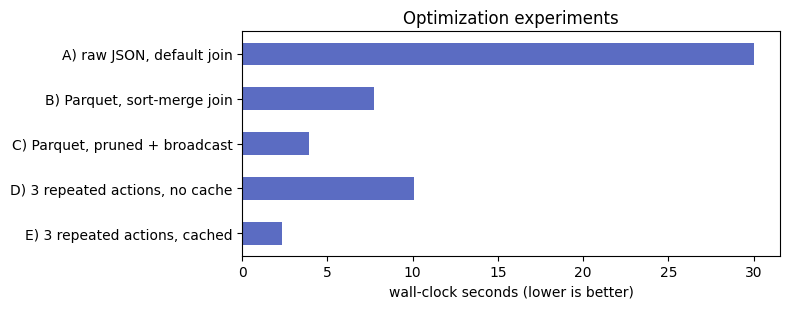

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
results["D) 3 repeated actions, no cache"] = t_nocache
results["E) 3 repeated actions, cached"] = t_cache
perf = pd.Series(results, name="seconds").round(2).to_frame()
display(perf)
ax = perf["seconds"].plot.barh(figsize=(8, 3.2), color="#5B6CC2")
ax.invert_yaxis(); ax.set_xlabel("wall-clock seconds (lower is better)"); ax.set_title("Optimization experiments")
plt.tight_layout(); plt.savefig(os.path.join(ROOT, "screenshots", "perf_experiments.png"), dpi=150); plt.show()

## 6. Write results
Outputs are written as Parquet. The large fact table is **partitioned by `review_year`** so downstream readers get partition pruning. The small summaries are coalesced to one file each to avoid many tiny files.

In [18]:
fact.cache()
_, _ = timed("write gold/review_facts (partitioned by year)", lambda:
    fact.repartition("review_year").write.mode("overwrite").partitionBy("review_year")
        .parquet(os.path.join(OUT, "gold", "review_facts")))
for name, df in {"brand_year_scorecard": brand_year, "category_year_trends": q1,
                 "verified_gap_by_category": q2, "overrated_products": q3,
                 "price_band_satisfaction": q4, "top_brands_by_category": q5}.items():
    timed(f"write gold/{name}", lambda df=df, name=name:
          df.coalesce(1).write.mode("overwrite").parquet(os.path.join(OUT, "gold", name)))

print("\nOutput folders:")
for p in sorted(glob.glob(os.path.join(OUT, "gold", "*"))):
    print(f"  {os.path.basename(p):<28s} {du(p)*1000:9.1f} MB")
print("\nRead-back check:", spark.read.parquet(os.path.join(OUT, "gold", "review_facts")).filter("review_year = 2022").count(), "rows in 2022 partition")

write gold/review_facts (partitioned by year)             46.84 s


write gold/brand_year_scorecard                            8.84 s


write gold/category_year_trends                            2.10 s


write gold/verified_gap_by_category                        1.90 s


write gold/overrated_products                              6.72 s


write gold/price_band_satisfaction                         5.73 s


write gold/top_brands_by_category                         15.30 s

Output folders:
  brand_year_scorecard               0.4 MB
  category_year_trends               0.0 MB
  overrated_products                 0.0 MB
  price_band_satisfaction            0.0 MB
  review_facts                     372.6 MB
  top_brands_by_category             0.0 MB
  verified_gap_by_category           0.0 MB



Read-back check: 1478731 rows in 2022 partition


## 7. Charts for the README

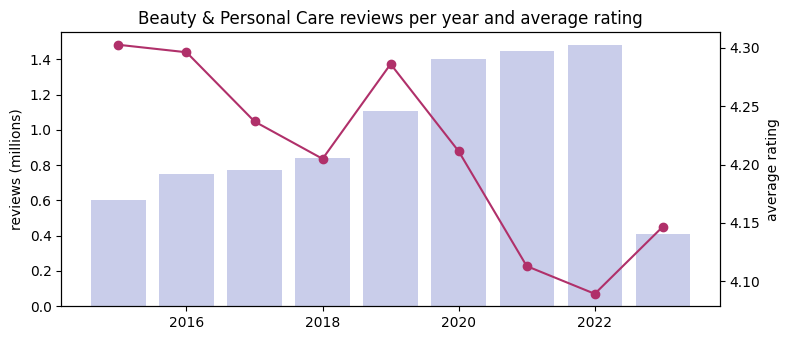

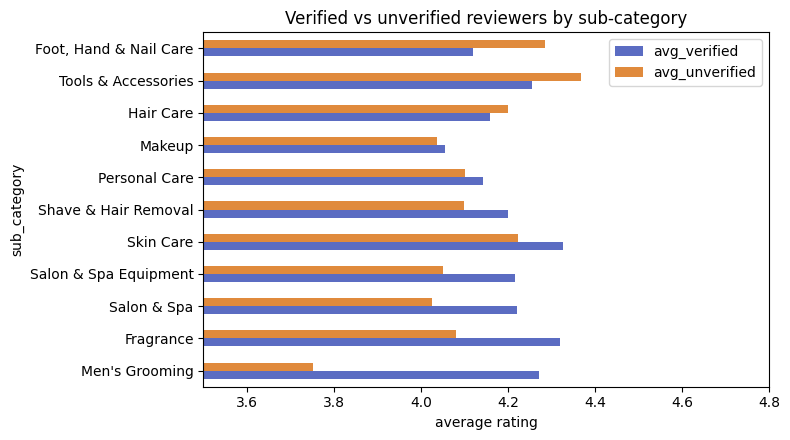

In [19]:
sc.setJobDescription("charts for README")
trend = spark.sql("""SELECT review_year, SUM(n_reviews) AS n_reviews,
                     SUM(avg_rating*n_reviews)/SUM(n_reviews) AS avg_rating
                     FROM category_year GROUP BY review_year ORDER BY review_year""").toPandas()
fig, ax1 = plt.subplots(figsize=(8, 3.5))
ax1.bar(trend.review_year, trend.n_reviews / 1e6, color="#C9CDEA"); ax1.set_ylabel("reviews (millions)")
ax2 = ax1.twinx(); ax2.plot(trend.review_year, trend.avg_rating, color="#B0306A", marker="o"); ax2.set_ylabel("average rating")
ax1.set_title("Beauty & Personal Care reviews per year and average rating")
plt.tight_layout(); plt.savefig(os.path.join(ROOT, "screenshots", "trend_by_year.png"), dpi=150); plt.show()

gap = q2.toPandas().sort_values("gap")
ax = gap.plot.barh(x="sub_category", y=["avg_verified", "avg_unverified"], figsize=(8, 4.5), color=["#5B6CC2", "#E08A3C"])
ax.set_xlim(3.5, 4.8); ax.set_xlabel("average rating"); ax.set_title("Verified vs unverified reviewers by sub-category")
plt.tight_layout(); plt.savefig(os.path.join(ROOT, "screenshots", "verified_gap.png"), dpi=150); plt.show()

## 8. (Optional) MLlib: predicting a positive review from its text
A `Pipeline` of tokenizer → stop-word removal → bag of words → TF-IDF → logistic regression, trained on a random sample of 2022–2023 reviews (neutral 3-star reviews removed). The model's largest coefficients tell us which words drive positive and negative reviews.

In [20]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover, CountVectorizer, IDF
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

ml_df = (reviews.filter(F.col("review_year") >= 2022)
         .filter((F.col("rating") != 3) & F.col("text").isNotNull())
         .sample(fraction=0.08, seed=42)
         .select((F.col("rating") >= 4).cast("double").alias("label"),
                 F.concat_ws(" ", "title", "text").alias("doc")))
sc.setJobDescription("MLlib: text classifier")
train, test = ml_df.randomSplit([0.8, 0.2], seed=42)
train.cache()
print(f"train rows: {train.count():,} | positive share: {train.agg(F.avg('label')).first()[0]:.2f}")

pipe = Pipeline(stages=[
    RegexTokenizer(inputCol="doc", outputCol="tokens", pattern="[^a-z']+", toLowercase=True, minTokenLength=2),
    StopWordsRemover(inputCol="tokens", outputCol="words"),
    CountVectorizer(inputCol="words", outputCol="tf", vocabSize=20000, minDF=25),
    IDF(inputCol="tf", outputCol="features"),
    LogisticRegression(maxIter=30, regParam=0.01),
])
model, _ = timed("fit text classifier", lambda: pipe.fit(train))
pred = model.transform(test)
auc = BinaryClassificationEvaluator(metricName="areaUnderROC").evaluate(pred)
acc = pred.select(F.avg((F.col("prediction") == F.col("label")).cast("double"))).first()[0]
print(f"Test AUC = {auc:.3f} | accuracy = {acc:.3f}")

vocab = model.stages[2].vocabulary
coefs = model.stages[-1].coefficients.toArray()
words = pd.DataFrame({"word": vocab, "coef": coefs}).sort_values("coef")
print("Most NEGATIVE words:", ", ".join(words.head(15).word))
print("Most POSITIVE words:", ", ".join(words.tail(15).word[::-1]))
_ = train.unpersist()
sc.setJobDescription(None)

train rows: 111,773 | positive share: 0.82


26/11/24 20:35:39 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/24 20:35:39 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


fit text classifier                                       23.57 s


Test AUC = 0.958 | accuracy = 0.927
Most NEGATIVE words: disappointed, disappointing, waste, horrible, returned, meh, useless, awful, ghost, worst, poor, terrible, returnable, nope, scam
Most POSITIVE words: great, love, drastic, perfect, works, nice, amazing, cares, excellent, easy, best, awesome, good, friction, prompt


## 9. Wrap-up
The Spark UI for this run can be replayed with the History Server (`$SPARK_HOME/sbin/start-history-server.sh`, http://localhost:18080) because event logging was on. See the README for screenshots and the written performance analysis.

In [21]:
print("Application id:", sc.applicationId)
spark.stop()

Application id: local-1795570274807
